# Chapitre 5 - Cours 1 : anatomie d'un prompt et apprentissage en contexte

Le chapitre 5 du livre ouvre la partie « adaptation » : comment faire faire à un modèle de
fondation ce que l'on veut **sans toucher à ses poids** ? La réponse la plus simple et la plus
répandue est l'**ingénierie des prompts** (*prompt engineering*). Chip Huyen insiste : ce
n'est pas « bricoler des mots jusqu'à ce que ça marche », mais une discipline expérimentale
qui mérite la même rigueur qu'une expérience de ML (jeu d'évaluation, métrique, variance).

Ce premier cours couvre la section *Introduction to Prompting* et sa sous-section
*In-Context Learning: Zero-Shot and Few-Shot*. Nous allons **mesurer** plutôt que croire :

1. l'anatomie d'un prompt (description de tâche, exemples, tâche) et son coût en tokens ;
2. la robustesse d'un modèle aux perturbations du prompt ;
3. l'apprentissage en contexte : courbe de précision en fonction du nombre d'exemples ;
4. la sensibilité à l'**ordre** et au **choix** des exemples (et le biais de récence) ;
5. la distinction prompt / contexte et l'image de la « bibliothèque de programmes ».

Fil rouge : une petite tâche de **classification d'intentions de clients en français**
(livraison, remboursement, technique, compte), rédigée à la main dans
`aie/ch05_prompts.py`, évaluée sur Qwen2.5-0.5B-Instruct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)

## 1. Qu'est-ce qu'un prompt ? (section *Introduction to Prompting*)

**Motivation.** Un modèle de fondation sait faire « beaucoup de choses » ; le prompt est le
seul levier qui lui dit **laquelle** faire, ici et maintenant. Le livre décompose un prompt
en trois parties :

- la **description de la tâche** : ce que l'on veut, le rôle à jouer, le format de sortie ;
- des **exemples** de la tâche résolue (chaque exemple s'appelle un *shot*) ;
- la **tâche** concrète : la question, le document, le message à traiter.

**Intuition.** C'est la fiche de consignes qu'on donne à un stagiaire : « voici ton rôle,
voici deux dossiers déjà traités pour t'inspirer, voici le dossier du jour ».

Pour qu'un prompt fonctionne, le modèle doit **savoir suivre des instructions** (capacité
évaluée au chapitre 4). Un excellent prompt ne sauve pas un modèle qui n'obéit pas.

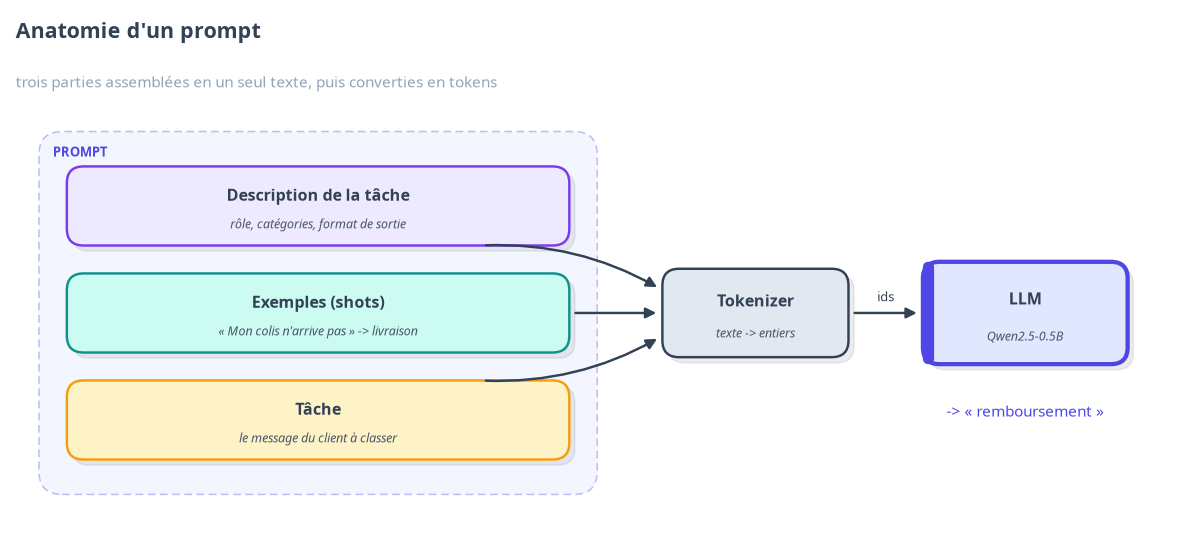

In [2]:
d = Diagram(12.5, 4.6, title="Anatomie d'un prompt",
            subtitle="trois parties assemblées en un seul texte, puis converties en tokens")
d.group(0.3, 0.35, 6.3, 4.25, "prompt", color=INDIGO)
d.box("desc", 3.3, 3.45, "Description de la tâche", sub="rôle, catégories, format de sortie",
      color=VIOLET, w=5.4, h=0.85)
d.box("ex", 3.3, 2.3, "Exemples (shots)", sub="« Mon colis n'arrive pas » -> livraison",
      color=TEAL, w=5.4, h=0.85)
d.box("task", 3.3, 1.15, "Tâche", sub="le message du client à classer", color=AMBER, w=5.4, h=0.85)
d.box("tok", 8.0, 2.3, "Tokenizer", sub="texte -> entiers", color=SLATE, w=2.0, h=0.95)
d.box("llm", 10.9, 2.3, "LLM", sub="Qwen2.5-0.5B", color=INDIGO, kind="model", w=2.2, h=1.1)
d.arrow("desc", "tok", rad=-0.15)
d.arrow("ex", "tok")
d.arrow("task", "tok", rad=0.15)
d.arrow("tok", "llm", "ids")
d.note(10.9, 1.25, "-> « remboursement »", color=INDIGO, fontsize=10, style="normal")
d.show()

Le module fournit `build_prompt` qui assemble les trois parties. Remarquez la dernière ligne
`Catégorie :` : c'est un **marqueur de fin** qui signale au modèle que la sortie structurée
doit commencer (nous en mesurerons l'importance au cours 3).

In [3]:
pool, test = P.split_intents(n_pool_per_class=4, seed=0)
print(f"{len(P.INTENT_DATA)} messages : {len(pool)} dans le réservoir d'exemples, {len(test)} en test")
shots4 = P.sample_shots(pool, 4, seed=1)
prompt = P.build_prompt(P.INTENT_DESCRIPTION, shots4, "J'attends mon remboursement depuis un mois.")
print(prompt)

56 messages : 16 dans le réservoir d'exemples, 40 en test
Tu es un assistant de service client. Classe chaque message de client dans une seule catégorie parmi : livraison, remboursement, technique, compte. Réponds uniquement par le nom de la catégorie.

Message : Est-ce que vous livrez en Belgique ?
Catégorie : livraison

Message : Je veux annuler ma commande et récupérer mon argent.
Catégorie : remboursement

Message : Je voudrais changer l'adresse e-mail associée à mon profil.
Catégorie : compte

Message : les notifications de l'appli ne marchent plus depuis hier
Catégorie : technique

Message : J'attends mon remboursement depuis un mois.
Catégorie :


Combien coûte chaque partie ? Comptons les tokens avec le tokenizer de Qwen. Le coût d'une
requête est (à peu près) linéaire en nombre de tokens d'entrée $n_\text{in}$ et de sortie
$n_\text{out}$ :
$$\text{coût} = n_\text{in}\, c_\text{in} + n_\text{out}\, c_\text{out},$$
et les exemples se paient **à chaque requête**.

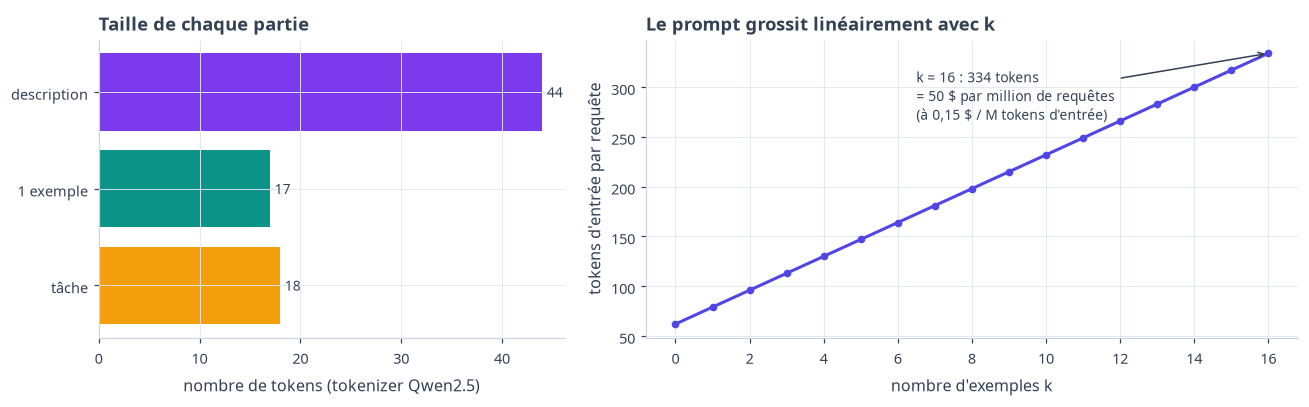

In [4]:
parts = {
    "description": P.INTENT_DESCRIPTION,
    "1 exemple": P.build_prompt("", shots4[:1], "x").split("\n\nMessage : x")[0],
    "tâche": "Message : J'attends mon remboursement depuis un mois.\nCatégorie :",
}
n_tok = {k: P.count_tokens(v) for k, v in parts.items()}
ks = np.arange(0, 17)
total = n_tok["description"] + n_tok["tâche"] + ks * n_tok["1 exemple"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.barh(list(n_tok)[::-1], list(n_tok.values())[::-1], color=[AMBER, TEAL, VIOLET])
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre de tokens (tokenizer Qwen2.5)")
ax.set_title("Taille de chaque partie")
ax = axes[1]
ax.plot(ks, total, "o-", color=INDIGO, ms=4)
ax.set_xlabel("nombre d'exemples k")
ax.set_ylabel("tokens d'entrée par requête")
ax.set_title("Le prompt grossit linéairement avec k")
cout = total[16] * 1e6 * 0.15 / 1e6
ax.annotate(f"k = 16 : {total[16]} tokens\n= {cout:.0f} $ par million de requêtes\n(à 0,15 $ / M tokens d'entrée)",
            xy=(16, total[16]), xytext=(6.5, total[16] * 0.8), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=SLATE))
finish(fig)
plt.show()

Le tarif de 0,15 $ par million de tokens d'entrée est un ordre de grandeur pour un petit
modèle hébergé : l'important est la **proportionnalité**. Chaque exemple ajouté doit donc
« rapporter » plus qu'il ne coûte, ce que nous mesurerons à la section 3.

> **À retenir.** Un prompt = description de la tâche + exemples + tâche. Tout est converti en
> tokens et facturé à chaque appel : les exemples sont un investissement récurrent.

## 2. Robustesse aux perturbations du prompt (section *Introduction to Prompting*)

Le livre propose un critère simple pour savoir **combien** d'ingénierie de prompt il faudra :
la **robustesse** du modèle aux petites perturbations (écrire « 5 » au lieu de « cinq »,
ajouter un saut de ligne, changer la casse). Plus le modèle est fragile, plus il faudra
tâtonner. On la mesure en perturbant le prompt et en observant la variation de la métrique.

**Méthode d'évaluation.** Pour mesurer la compréhension de la tâche indépendamment du format
de sortie, on utilise le **score des étiquettes** : on calcule la probabilité que le modèle
réponde chacune des 4 catégories et on prend la plus probable,
$$\hat y = \arg\max_{y \in \mathcal Y} \log p_\theta(y \mid \text{prompt}),$$
où $\log p_\theta(y\mid\cdot) = \sum_t \log p_\theta(y_t \mid \text{prompt}, y_{<t})$ somme les
log-probabilités des tokens de l'étiquette. C'est déterministe et ne demande qu'un passage
avant du modèle par message.

In [5]:
variantes = {
    "originale": P.INTENT_DESCRIPTION,
    "minuscules": P.INTENT_DESCRIPTION.lower(),
    "saut de ligne": P.INTENT_DESCRIPTION.replace(". ", ".\n"),
    "liste numérotée": ("Tu es un assistant de service client. Classe le message dans une catégorie :\n"
                        "1. livraison\n2. remboursement\n3. technique\n4. compte\n"
                        "Réponds uniquement par le nom de la catégorie."),
    "sans rôle": ("Classe chaque message de client dans une seule catégorie parmi : livraison, "
                  "remboursement, technique, compte. Réponds uniquement par le nom de la catégorie."),
    "en anglais": ("You are a customer service assistant. Classify each customer message into exactly "
                   "one category among: livraison, remboursement, technique, compte. "
                   "Answer only with the category name."),
}
rows = []
for nom, desc in variantes.items():
    for k in [0, 4]:
        acc = P.accuracy_at_k(test, P.sample_shots(pool, k, seed=1), description=desc)
        rows.append(dict(variante=nom, k=k, precision=acc))
rob = pd.DataFrame(rows).pivot(index="variante", columns="k", values="precision").loc[list(variantes)]
rob.columns = ["0 exemple", "4 exemples"]
rob.round(3)

,0 exemple,4 exemples
variante,,
originale,0.475,0.675
minuscules,0.500,0.600
saut de ligne,0.400,0.600
liste numérotée,0.375,0.675
sans rôle,0.375,0.575
en anglais,0.450,0.650


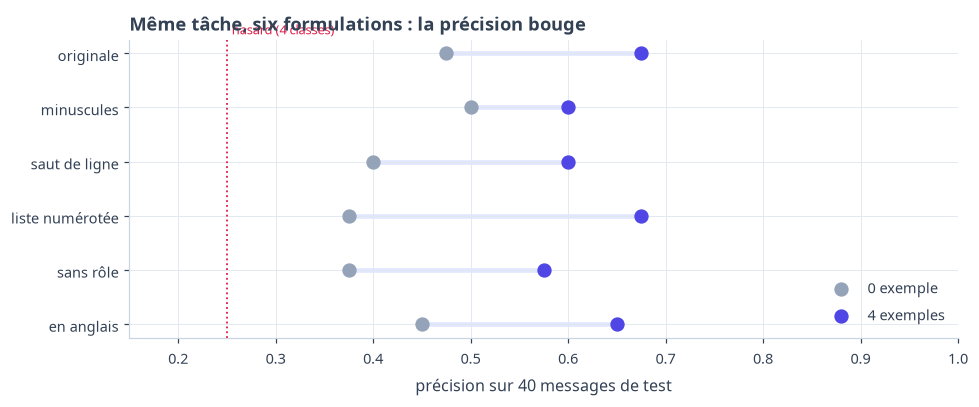

écart max-min (0 exemple) : 0.125 | (4 exemples) : 0.1


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(rob))
for j, (col, c) in enumerate(zip(rob.columns, [GRAY, INDIGO])):
    ax.scatter(rob[col], y, s=70, color=c, label=col, zorder=3)
for i in range(len(rob)):
    ax.plot(rob.iloc[i], [i, i], color=LIGHT[INDIGO], lw=3, zorder=1)
ax.set_yticks(y, rob.index)
ax.invert_yaxis()
ax.axvline(0.25, color=ROSE, ls=":", lw=1.2)
ax.text(0.255, -0.35, "hasard (4 classes)", color=ROSE, fontsize=8.5)
ax.set_xlim(0.15, 1.0)
ax.set_xlabel(f"précision sur {len(test)} messages de test")
ax.set_title("Même tâche, six formulations : la précision bouge")
ax.legend(loc="lower right")
finish(fig)
plt.show()
print("écart max-min (0 exemple) :", round(rob['0 exemple'].max() - rob['0 exemple'].min(), 3),
      "| (4 exemples) :", round(rob['4 exemples'].max() - rob['4 exemples'].min(), 3))

**Lecture.** Des modifications qu'un humain jugerait anodines (casse, sauts de ligne,
langue de la consigne) déplacent la précision de plusieurs points sur ce petit modèle : la
sortie d'un modèle de 0,5 milliard de paramètres est **fragile**. Avec 40 messages de test,
un écart de 1 message vaut 2,5 points : il faut garder en tête cette granularité (et
l'incertitude statistique, voir l'exercice 5.9) avant de conclure qu'une formulation est
« meilleure ». Le livre note que la robustesse croît avec la capacité du modèle : passer à
un modèle plus fort réduit souvent le temps passé à tâtonner.

> **À retenir.** La robustesse aux perturbations se **mesure** : on perturbe le prompt et
> on regarde la dispersion de la métrique. Une forte dispersion signale qu'il faudra
> beaucoup d'itérations (ou un modèle plus robuste).

## 3. Apprentissage en contexte : zéro-shot et few-shot (section *In-Context Learning: Zero-Shot and Few-Shot*)

**Motivation.** Traditionnellement, un modèle apprend un comportement en **mettant à jour
ses poids** (pré-entraînement, post-entraînement, finetuning). L'article de GPT-3 (Brown et
al., 2020) a montré qu'un modèle de langage peut aussi apprendre une tâche **à partir
d'exemples placés dans le prompt**, sans aucune mise à jour : c'est l'apprentissage en
contexte (*in-context learning*). Avec $k$ exemples on parle de *k-shot* ; sans exemple, de
*zero-shot*.

**Intuition.** Les exemples ne « réentraînent » pas le modèle : ils **conditionnent** sa
distribution. Formellement, on passe de $p_\theta(y \mid x)$ à
$p_\theta(y \mid (x_1, y_1), \dots, (x_k, y_k), x)$ : mêmes paramètres $\theta$, contexte plus
riche. Les exemples précisent le format attendu, l'espace des étiquettes et la frontière
entre classes ambiguës.

**Deux façons de présenter les exemples à un modèle de conversation :**

- **en ligne** (*inline*) : description, exemples et tâche dans un seul message utilisateur ;
- **en tours de conversation** (*chat*) : la description va dans le prompt système et
  chaque exemple devient un échange utilisateur / assistant, comme si le modèle avait déjà
  répondu correctement $k$ fois.

Mesurons la précision en fonction de $k$ pour les deux présentations. Pour chaque $k$ on
tire plusieurs jeux d'exemples (équilibrés entre classes) afin d'estimer la **variance due au
choix des exemples**.

In [7]:
K_GRID = [0, 1, 2, 4, 8, 12, 16]
N_DRAWS = 5
curve = []
for fmt, draws in [("chat", N_DRAWS), ("inline", 3)]:
    for k in K_GRID:
        for s in range(draws if k else 1):
            acc = P.accuracy_at_k(test, P.sample_shots(pool, k, seed=s), shot_format=fmt)
            curve.append(dict(format=fmt, k=k, tirage=s, precision=acc))
curve = pd.DataFrame(curve)
resume = curve.groupby(["format", "k"]).precision.agg(["mean", "min", "max"]).round(3)
resume.unstack(0)

mean           min           max       
format   chat inline   chat inline   chat inline
k                                               
0       0.475  0.425  0.475  0.425  0.475  0.425
1       0.465  0.417  0.400  0.350  0.575  0.500
2       0.535  0.342  0.475  0.325  0.625  0.375
4       0.635  0.292  0.550  0.250  0.675  0.350
8       0.670  0.392  0.650  0.250  0.700  0.500
12      0.705  0.367  0.675  0.275  0.750  0.500
16      0.740  0.342  0.725  0.250  0.775  0.450

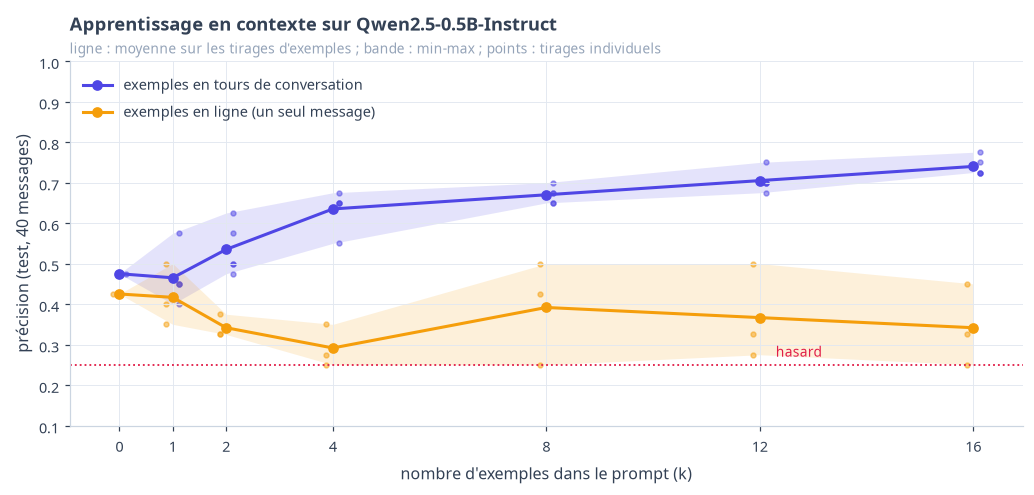

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for fmt, c, lab in [("chat", INDIGO, "exemples en tours de conversation"), ("inline", AMBER, "exemples en ligne (un seul message)")]:
    g = curve[curve.format == fmt]
    m = g.groupby("k").precision.mean()
    lo, hi = g.groupby("k").precision.min(), g.groupby("k").precision.max()
    ax.fill_between(m.index, lo, hi, color=c, alpha=0.15, lw=0)
    ax.plot(m.index, m.values, "o-", color=c, label=lab)
    ax.scatter(g.k + (0.12 if fmt == "chat" else -0.12), g.precision, s=10, color=c, alpha=0.5)
ax.axhline(0.25, color=ROSE, ls=":", lw=1.2)
ax.text(12.3, 0.27, "hasard", color=ROSE, fontsize=9)
ax.set_xticks(K_GRID)
ax.set_ylim(0.1, 1.0)
ax.set_xlabel("nombre d'exemples dans le prompt (k)")
ax.set_ylabel("précision (test, 40 messages)")
ax.set_title("Apprentissage en contexte sur Qwen2.5-0.5B-Instruct", pad=20)
subtitle(ax, "ligne : moyenne sur les tirages d'exemples ; bande : min-max ; points : tirages individuels")
ax.legend(loc="upper left")
finish(fig)
plt.show()

**Lecture.** Deux enseignements, tous deux mesurés :

1. **En tours de conversation, les exemples aident nettement** : la précision moyenne
   progresse de façon presque monotone avec $k$, avec des rendements décroissants. C'est
   l'effet décrit par l'article GPT-3 : sans mise à jour des poids, le modèle exploite les
   exemples.
2. **La présentation compte autant que le nombre d'exemples.** Les mêmes exemples placés
   « en ligne » dans un seul message n'apportent rien de fiable à ce petit modèle, et les
   résultats varient énormément d'un tirage à l'autre. Les modèles de conversation ont été
   post-entraînés sur des dialogues : un tour assistant ressemble à « ce que j'ai déjà
   répondu », un bloc de texte non.

Le livre rapporte que l'apport du few-shot diminue pour les modèles très forts (GPT-4 dans
une analyse de Microsoft de 2023) car ils comprennent mieux les instructions, mais qu'il
reste précieux sur des domaines peu vus à l'entraînement. Pour un modèle de 0,5 B, les
exemples restent très utiles... à condition de bien les présenter.

Regardons **où** les exemples aident, avec les matrices de confusion à 0 et 16 exemples.

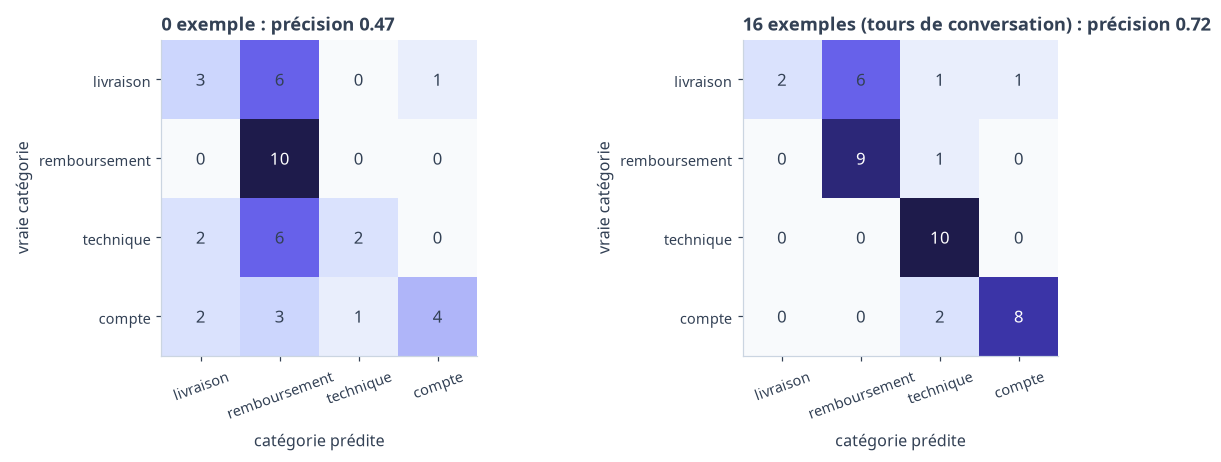

In [9]:
labs0, _ = P.predictions(test, [])
labs16, _ = P.predictions(test, P.sample_shots(pool, 16, seed=0))
y_true = [y for _, y in test]

def confusion(y_true, y_pred, labels=P.INTENT_LABELS):
    m = np.zeros((len(labels), len(labels)), dtype=int)
    for a, b in zip(y_true, y_pred):
        m[labels.index(a), labels.index(b)] += 1
    return m

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, preds, titre in [(axes[0], labs0, "0 exemple"), (axes[1], labs16, "16 exemples (tours de conversation)")]:
    m = confusion(y_true, preds)
    ax.imshow(m, cmap="aie_seq", vmin=0, vmax=10)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=11,
                    color="white" if m[i, j] > 6 else SLATE)
    ax.set_xticks(range(4), P.INTENT_LABELS, rotation=20)
    ax.set_yticks(range(4), P.INTENT_LABELS)
    ax.set_xlabel("catégorie prédite")
    ax.set_ylabel("vraie catégorie")
    ax.grid(False)
    acc = np.mean([a == b for a, b in zip(y_true, preds)])
    ax.set_title(f"{titre} : précision {acc:.2f}")
finish(fig)
plt.show()

Sans exemple, le modèle concentre ses prédictions sur une catégorie « fourre-tout »
(ici, surtout « remboursement ») : il projette sur les étiquettes sa propre lecture des mots
du message. Les exemples redessinent les frontières : « technique » et « compte » deviennent
presque parfaites. Une confusion persiste entre livraison et remboursement, et elle n'est
pas absurde : un colis abîmé ou incomplet débouche souvent sur une demande d'argent. C'est
typiquement le cas où il faut **préciser la consigne** (« un problème de colis relève de
livraison, même si le client parle d'argent ») ou choisir des exemples à la frontière.

> **À retenir.** L'apprentissage en contexte conditionne le modèle sans changer ses poids.
> Le gain dépend du nombre d'exemples (rendements décroissants), du modèle, et de la
> **présentation** : pour un modèle de conversation, des tours utilisateur / assistant
> fonctionnent bien mieux qu'un bloc de texte.